# Lab 4 적용 — 평가지표와 알고리즘 비교 (Give Me Some Credit)

**Lab 3에서 넘어온 질문:** 어떤 알고리즘이 연체자를 가장 잘 골라낼까? 정확도 말고 무엇으로 봐야 할까?

Lab 4의 순서를 그대로 따른다.
1. 평가지표: 정확도 → logloss → AUC → ROC 곡선 → 혼동행렬 → 분류 리포트
2. 알고리즘 후보 점검(spot-check): LR, KNN, SVM, CART
3. 알고리즘 6개 비교: LR, LDA, KNN, CART, NB, SVM (같은 10-fold, 같은 seed) + 상자그림

Lab 3의 결론대로 평가는 **층화 10-fold**(seed 7), 데이터는 Lab 2의 결론인 **로그+표준화**를 쓴다.

In [1]:
import glob, os, time
import numpy
from pandas import read_csv, DataFrame
from matplotlib import pyplot, font_manager
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    font_manager.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, VIOLET, INK = '#3182F6', '#F04452', '#B0B8C1', '#7C5CFF', '#191F28'
numpy.set_printoptions(precision=3, suppress=True)

filename = '../data/givemesomecredit.csv'
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
features = names[1:]
dataframe = read_csv(filename, names=names, header=0)
array = dataframe.values
X = array[:, 1:9].astype(float)
Y = array[:, 0].astype(int)
Xlog = X.copy()
for c in ['revol', 'late30', 'debt', 'income']:
    Xlog[:, features.index(c)] = numpy.log1p(Xlog[:, features.index(c)])
Xs = StandardScaler().fit_transform(Xlog)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)   # Lab 3 결론: 층화 10-fold
print(Xs.shape, '연체 비율', Y.mean().round(4))

(150000, 8) 연체 비율 0.0668


## 1. 평가지표 (모두 로지스틱 회귀 + 층화 10-fold)
### 1-1. 정확도 (Lab 4: `scoring = 'accuracy'`)

In [2]:
model = LogisticRegression(solver='liblinear')
results = cross_val_score(model, Xs, Y, cv=kfold, scoring='accuracy')
print("Accuracy: %.3f (%.3f)" % (results.mean(), results.std()))
print("'전부 정상' 기준선: %.3f" % (1 - Y.mean()))

Accuracy: 0.932 (0.001)
'전부 정상' 기준선: 0.933


**(a)(b)** 정확도 93.2%. 그런데 모두 정상이라고 찍어도 93.3%다. **(c)** 표준편차는 10번 시험 점수의 흩어짐(√평균 제곱 편차)이다.
데이터가 바뀌어도 성능이 비슷한지(안정성)를 보여 준다. 여기서는 0.0006으로 매우 작다.

### 1-2. Logloss (Lab 4: `scoring = 'neg_log_loss'`)

In [3]:
results = cross_val_score(model, Xs, Y, cv=kfold, scoring='neg_log_loss')
print("Logloss: %.3f (%.3f)" % (results.mean(), results.std()))
p0 = Y.mean()
print("확률을 늘 %.4f로 말하는 모델의 logloss: %.3f" % (p0, -(p0 * numpy.log(p0) + (1 - p0) * numpy.log(1 - p0))))

Logloss: -0.199 (0.003)
확률을 늘 0.0668로 말하는 모델의 logloss: 0.245


**(d)(e)** logloss 0.199 (sklearn은 '클수록 좋음'으로 맞추려고 음수로 보고한다). 아무 정보 없이 늘 6.68%라고 말하는 모델은 0.245이므로,
모델의 확률이 그보다는 낫다. 0이 완벽이다.

### 1-3. AUC (Lab 4: `scoring = 'roc_auc'`)

In [4]:
results = cross_val_score(model, Xs, Y, cv=kfold, scoring='roc_auc')
print("AUC: %.3f (%.3f)" % (results.mean(), results.std()))

AUC: 0.824 (0.009)


**(f)(g)** AUC 0.824 → Lab 4의 등급표로 0.80~0.90 = good(B). 연체자를 정상 고객보다 더 위험하게 줄 세우는 능력이 있다.

### 1-4. ROC 곡선 (Lab 4: `roc_curve`, `roc_auc_score`) — 혼동행렬·리포트와 같은 분할(33%, seed 7) 사용

In [5]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report, recall_score, precision_score
X_train, X_test, Y_train, Y_test = train_test_split(Xs, Y, test_size=0.33, random_state=7, stratify=Y)
model = LogisticRegression(solver='liblinear')
model.fit(X_train, Y_train)
probs = model.predict_proba(X_test)[:, 1]
print('AUC: %.3f' % roc_auc_score(Y_test, probs))
fpr, tpr, thresholds = roc_curve(Y_test, probs)
print('시험 데이터', len(Y_test), '명 중 연체자', Y_test.sum(), '명')

AUC: 0.827
시험 데이터 49500 명 중 연체자 3309 명


### 1-5. 혼동행렬 (Lab 4: `confusion_matrix`)

In [6]:
predicted = model.predict(X_test)            # 기본 판정 기준: 확률 0.5
matrix = confusion_matrix(Y_test, predicted)
print(matrix)
tn, fp, fn, tp = matrix.ravel()
print(f'연체자 {tp + fn}명 중 잡은 사람 {tp}명 ({tp / (tp + fn):.1%})')
print(f'1종 오류(정상인데 연체로 판정, FP) {fp}명 · 2종 오류(연체자를 정상으로 판정, FN) {fn}명')

[[46116    75]
 [ 3266    43]]
연체자 3309명 중 잡은 사람 43명 (1.3%)
1종 오류(정상인데 연체로 판정, FP) 75명 · 2종 오류(연체자를 정상으로 판정, FN) 3266명


**(i)** 1종 오류(FP) = 정상 고객을 연체로 판정 → 대출을 거절해 이자 수익을 잃는다. 2종 오류(FN) = 연체자를 정상으로 판정 → 원금을 잃는다.
**(j)** 이 문제에서는 **2종 오류가 더 비싸다.** 그런데 기준 0.5에서는 연체자 3,309명 중 43명(1.3%)만 잡았다. 정확도 93%는 거의 '전부 정상'이라고 말한 결과다.

### 1-6. 분류 리포트 (Lab 4: `classification_report`)

In [7]:
print(classification_report(Y_test, predicted, digits=3))

              precision    recall  f1-score   support

           0      0.934     0.998     0.965     46191
           1      0.364     0.013     0.025      3309

    accuracy                          0.933     49500
   macro avg      0.649     0.506     0.495     49500
weighted avg      0.896     0.933     0.902     49500



**(k)** 연체(1)의 recall이 0.013이다. precision은 '연체라고 한 사람 중 진짜 연체자 비율', recall은 '진짜 연체자 중 잡아낸 비율'이다.

### 1-7. 판정 기준을 바꾸면? — 연체자를 더 잡는 두 가지 방법 (Lab 4 (j)의 답을 실제로 확인)
① 판정 기준(threshold)을 0.5보다 낮춘다. ② 학습할 때 연체자에 더 큰 가중치를 준다(`class_weight='balanced'`, 연체 1명 = 정상 약 14명).

In [8]:
rows = []
for t in [0.5, 0.3, 0.2, 0.1]:
    pr = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(Y_test, pr).ravel()
    rows.append((f'기준 {t}', tp, fn, fp, recall_score(Y_test, pr), precision_score(Y_test, pr), pr.mean()))
bal = LogisticRegression(solver='liblinear', class_weight='balanced').fit(X_train, Y_train)
pb = bal.predict(X_test)
tn, fp, fn, tp = confusion_matrix(Y_test, pb).ravel()
rows.append(('가중치 balanced', tp, fn, fp, recall_score(Y_test, pb), precision_score(Y_test, pb), pb.mean()))
table = DataFrame(rows, columns=['방법', '잡은 연체자(TP)', '놓친 연체자(FN)', '잘못 거절(FP)', 'recall', 'precision', '연체로 판정한 비율'])
print(table.round(3).to_string(index=False))
print(confusion_matrix(Y_test, pb))

          방법  잡은 연체자(TP)  놓친 연체자(FN)  잘못 거절(FP)  recall  precision  연체로 판정한 비율
      기준 0.5          43        3266         75   0.013      0.364       0.002
      기준 0.3         569        2740        880   0.172      0.393       0.029
      기준 0.2        1701        1608       4037   0.514      0.296       0.116
      기준 0.1        2244        1065       7708   0.678      0.225       0.201
가중치 balanced        2478         831       9766   0.749      0.202       0.247
[[36425  9766]
 [  831  2478]]


In [9]:
# 가중치는 판정 기준만이 아니라 순위(AUC)도 바꾼다 → 층화 10-fold로 확인
for label, m in [('기본', LogisticRegression(solver='liblinear')),
                 ('가중치 balanced', LogisticRegression(solver='liblinear', class_weight='balanced'))]:
    r = cross_val_score(m, Xs, Y, cv=kfold, scoring='roc_auc')
    print("%s AUC: %.4f (%.4f)" % (label, r.mean(), r.std()))

기본 AUC: 0.8240 (0.0088)


가중치 balanced AUC: 0.8436 (0.0073)


기준을 0.2로 낮추면 연체자의 절반(51%)을 잡고, 가중치를 주면 75%를 잡는다. 대신 연체로 판정한 사람 중 진짜 연체자는 20%로 내려간다
(그래도 무작위로 고르면 6.7%이니 3배 정확하다). 그리고 가중치를 주자 **AUC 자체가 0.824 → 0.844로 올랐다.**
선형 모델은 다수(정상) 쪽을 맞추는 데 치우쳐 학습되는데, 가중치가 연체자 쪽 경계를 더 신경 쓰게 만들었기 때문으로 보인다.

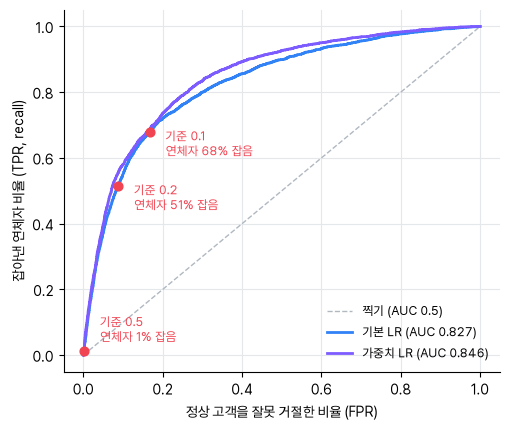

In [10]:
# 그림: ROC 곡선 위에 판정 기준별 위치
bprobs = bal.predict_proba(X_test)[:, 1]
bfpr, btpr, _ = roc_curve(Y_test, bprobs)
fig, ax = pyplot.subplots(figsize=(5.2, 4.4))
ax.plot([0, 1], [0, 1], ls='--', color=GRAY, lw=1, label='찍기 (AUC 0.5)')
ax.plot(fpr, tpr, color=BLUE, lw=2, label=f'기본 LR (AUC {roc_auc_score(Y_test, probs):.3f})')
ax.plot(bfpr, btpr, color=VIOLET, lw=2, label=f'가중치 LR (AUC {roc_auc_score(Y_test, bprobs):.3f})')
for t, dx, dy in [(0.5, 0.04, 0.03), (0.2, 0.04, -0.07), (0.1, 0.04, -0.07)]:
    pr = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(Y_test, pr).ravel()
    x, y = fp / (fp + tn), tp / (tp + fn)
    ax.scatter(x, y, color=RED, s=40, zorder=5)
    ax.annotate(f'기준 {t}\n연체자 {y:.0%} 잡음', (x, y), (x + dx, y + dy), fontsize=9, color=RED)
ax.set_xlabel('정상 고객을 잘못 거절한 비율 (FPR)'); ax.set_ylabel('잡아낸 연체자 비율 (TPR, recall)')
ax.legend(loc='lower right', fontsize=9, frameon=False)
ax.spines[['top', 'right']].set_visible(False); ax.grid(color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab4_roc.png', dpi=200); pyplot.show()

**(h)** 곡선이 왼쪽 위로 붙을수록 좋다. 점선(찍기)보다 확실히 위에 있다. 빨간 점은 판정 기준에 따른 위치로, 기준 0.5는 곡선 맨 아래(거의 아무도 연체로 판정 안 함)에 있다.

## 2·3. 알고리즘 6개 비교 (Lab 4: LR · LDA · KNN · CART · NB · SVM, 같은 10-fold · 같은 seed)
Lab 4는 정확도로 비교하지만, 1에서 본 대로 정확도는 차이를 못 보여 주므로 **AUC로 비교**한다. 정확도도 함께 기록한다.

In [11]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
models = []
models.append(('LR', LogisticRegression(solver='liblinear')))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('CART', DecisionTreeClassifier(random_state=7)))
models.append(('NB', GaussianNB()))
results, accs, names_, secs = [], [], [], []
for name, model in models:
    t0 = time.time()
    cv_auc = cross_val_score(model, Xs, Y, cv=kfold, scoring='roc_auc', n_jobs=-1)
    cv_acc = cross_val_score(model, Xs, Y, cv=kfold, scoring='accuracy', n_jobs=-1)
    results.append(cv_auc); accs.append(cv_acc); names_.append(name); secs.append(time.time() - t0)
    print("%s: AUC %f (%f) · 정확도 %f · %.1f초" % (name, cv_auc.mean(), cv_auc.std(), cv_acc.mean(), secs[-1]))

LR: AUC 0.823953 (0.008833) · 정확도 0.932193 · 8.7초


LDA: AUC 0.831758 (0.008231) · 정확도 0.927513 · 1.0초


KNN: AUC 0.726967 (0.007046) · 정확도 0.927713 · 12.5초


CART: AUC 0.595195 (0.005786) · 정확도 0.893567 · 7.2초


NB: AUC 0.822189 (0.009425) · 정확도 0.881273 · 1.0초


### SVM은 15만 건에서 얼마나 걸릴까? — 표본 크기별 학습 시간을 재서 추정

In [12]:
sizes, fit_secs = [2500, 5000, 10000, 20000], []
for n in sizes:
    idx, _ = train_test_split(numpy.arange(len(Y)), train_size=n, random_state=7, stratify=Y)
    t0 = time.time(); SVC().fit(Xs[idx], Y[idx]); fit_secs.append(time.time() - t0)
    print(f'SVM 학습 {n:>6,}건: {fit_secs[-1]:.2f}초')
slope = numpy.polyfit(numpy.log(sizes), numpy.log(fit_secs), 1)[0]
full = fit_secs[-1] * (135000 / sizes[-1]) ** slope
print(f'데이터 2배 → 시간 약 {2 ** slope:.1f}배 (n^{slope:.2f})')
print(f'13.5만 건(10-fold 한 번의 학습량) 추정: {full / 60:.1f}분 → 10-fold 약 {full * 10 / 3600:.1f}시간 (예측 시간 제외)')

SVM 학습  2,500건: 0.09초


SVM 학습  5,000건: 0.41초


SVM 학습 10,000건: 2.15초


SVM 학습 20,000건: 8.81초
데이터 2배 → 시간 약 4.7배 (n^2.22)
13.5만 건(10-fold 한 번의 학습량) 추정: 10.1분 → 10-fold 약 1.7시간 (예측 시간 제외)


In [13]:
# 그래서 SVM은 1만 건 층화 표본에서 비교한다. 같은 표본에서 다른 5개도 함께 돌려 공정하게 비교한다.
idx, _ = train_test_split(numpy.arange(len(Y)), train_size=10000, random_state=7, stratify=Y)
sample = {}
for name, model in models + [('SVM', SVC()), ('SVM 가중치', SVC(class_weight='balanced'))]:
    r = cross_val_score(model, Xs[idx], Y[idx], cv=kfold, scoring='roc_auc', n_jobs=-1)
    sample[name] = r
    print("[1만 건 표본] %s: AUC %.4f (%.4f)" % (name, r.mean(), r.std()))

[1만 건 표본] LR: AUC 0.8232 (0.0327)
[1만 건 표본] LDA: AUC 0.8263 (0.0281)


[1만 건 표본] KNN: AUC 0.7031 (0.0340)


[1만 건 표본] CART: AUC 0.5856 (0.0286)
[1만 건 표본] NB: AUC 0.8109 (0.0316)


[1만 건 표본] SVM: AUC 0.5787 (0.0270)


[1만 건 표본] SVM 가중치: AUC 0.8097 (0.0296)


**SVM 결과:** 1만 건 표본에서 AUC 0.579로 찍기 수준이다. 정상 고객이 93%라서 SVM이 '거의 다 정상'인 경계를 긋기 때문이다.
연체자에 가중치를 주면 0.810으로 회복된다. 하지만 15만 건 전체로는 10-fold에 1시간 이상 걸려 이번 비교에서는 표본 결과만 쓴다.

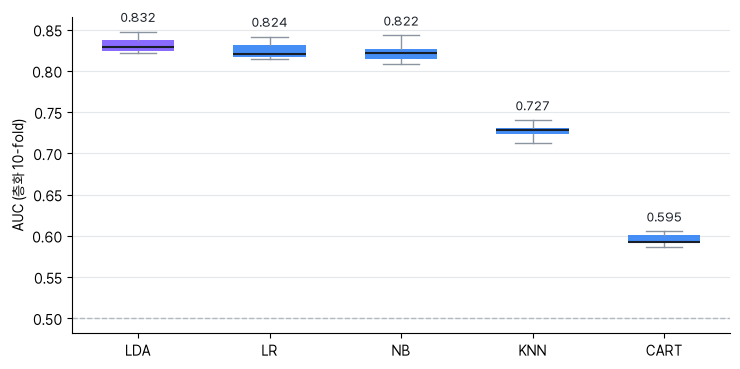

In [14]:
# 그림: 알고리즘별 10번 시험 AUC 상자그림 (Lab 4의 boxplot) — 15만 건 전체 결과만. SVM(1만 건 표본)은 조건이 달라 따로 표시
data = list(results)
labels = list(names_)
order = numpy.argsort([-numpy.mean(d) for d in data])
fig, ax = pyplot.subplots(figsize=(7.5, 3.8))
bp = ax.boxplot([data[i] for i in order], patch_artist=True, widths=0.55,
                medianprops={'color': INK, 'lw': 1.5}, whiskerprops={'color': '#8B95A1'}, capprops={'color': '#8B95A1'},
                flierprops={'marker': 'o', 'markersize': 3, 'markeredgecolor': '#8B95A1'})
for patch, i in zip(bp['boxes'], order):
    patch.set_facecolor(VIOLET if labels[i] == 'LDA' else (GRAY if labels[i].startswith('SVM') else BLUE))
    patch.set_edgecolor('none'); patch.set_alpha(0.9 if not labels[i].startswith('SVM') else 0.6)
for k, i in enumerate(order):
    ax.text(k + 1, numpy.max(data[i]) + 0.012, f'{numpy.mean(data[i]):.3f}', ha='center', fontsize=9.5, color=INK)
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([labels[i] for i in order], fontsize=10)
ax.axhline(0.5, ls='--', color=GRAY, lw=1)
ax.set_ylabel('AUC (층화 10-fold)'); ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab4_compare.png', dpi=200); pyplot.show()

**(n)(o) 해석:** 15만 건 전체에서 LDA 0.832 > LR 0.824 ≈ NB 0.822 > KNN 0.727 > CART 0.595.
정확도는 모두 89~93%로 기준선 근처라 차이를 보여 주지 못한다.
- 선형 계열(LDA, LR)과 NB가 상위권이다. 변수 8개의 관계가 비교적 단순(직선에 가까움)하다는 뜻이다.
- CART는 깊이 제한이 없어 학습 데이터를 외웠다(과적합). KNN은 기본 k=5라 확률이 0, 0.2, …, 1 여섯 단계뿐이어서 줄 세우기가 거칠다.
- 더 볼 만한 후보: **LDA와 LR**(Lab 4 원문 결론과 같음). 트리는 하나로는 약하니 Lab 5의 앙상블로 다시 본다.

## 정리: 발견 → 다음 질문
- 발견 1: 기준 0.5에서 정확도 93%지만 **연체자 3,309명 중 43명(1.3%)만 잡았다.** 연체자 가중치를 주면 75%를 잡고 AUC도 0.844로 오른다.
- 발견 2: 기본 설정 6개 중 **LDA 0.832가 1위**, 선형 계열이 강하다. SVM은 15만 건에 1시간 이상이라 표본으로만 확인했다.

**목표(연체 예측)에 대한 결론:** 연체자 가중치를 기본으로 쓰고, 판정 기준은 '놓친 연체자 비용'을 보고 정한다. 후보는 LR·LDA, 그리고 앙상블.

**다음 질문 (Lab 5):** 지금까지 변환을 전체 데이터에 먼저 맞췄는데(누수), 이를 바로잡고 데이터를 정리하고 앙상블·튜닝을 하면 더 오를까?